# Robot IMU Signal Filtering and Comparison

In this project, I simulated the angular velocity measurements of a mobile robot using an IMU gyroscope. The robot moves straight and makes left and right turns. To simulate measurement errors, I added random sensor noise and motor vibration. The motor vibration changes in both amplitude and frequency during the simulation.

The main goal is to reduce the measurement noise while preserving the robot's actual turning motion. I implemented four filtering methods: FIR, IIR, LMS, and NLMS. I compared their performance using RMSE and their response to sudden changes in angular velocity. For the adaptive filters, I also used a motor reference signal to estimate and cancel the vibration.

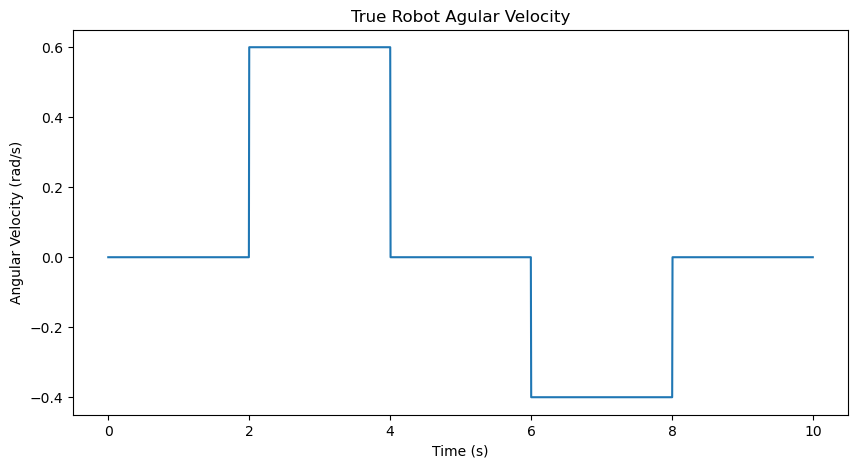

In [3]:
import numpy as np
import matplotlib.pyplot as plt

fs, duration = 200, 10
N = fs * duration
t = np.arange(N) / fs

# Actual robot angular velocity
omega_true = np.zeros(N)

mask_left = (t >= 2) & (t <= 4)
omega_true[mask_left] = 0.6
mask_right = (t >= 6) & (t <= 8)
omega_true[mask_right] = -0.4

# Plotting omega_true against t
plt.figure(figsize=(10, 5))
plt.plot(t, omega_true)
plt.title("True Robot Agular Velocity")
plt.xlabel("Time (s)")
plt.ylabel("Angular Velocity (rad/s)")
plt.show()

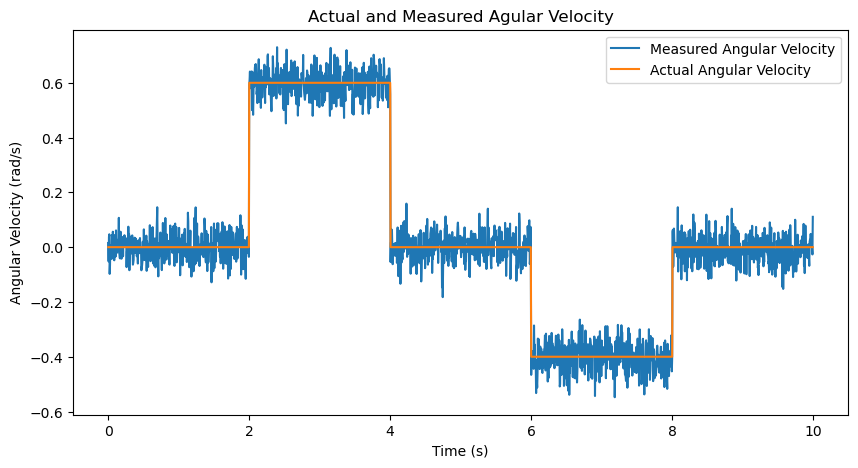

In [5]:
rng = np.random.default_rng(42)
# Standard deviation in rad/s
noise_std = 0.05
sensor_noise = rng.normal(0, noise_std, N)
gyro_measured = omega_true + sensor_noise

# Plotting both omega_true annd gyro_measured against time
plt.figure(figsize=(10, 5))
plt.plot(t, gyro_measured, label="Measured Angular Velocity")
plt.plot(t, omega_true, label="Actual Angular Velocity")
plt.title("Actual and Measured Agular Velocity")
plt.xlabel("Time (s)")
plt.ylabel("Angular Velocity (rad/s)")
plt.legend()
plt.show()

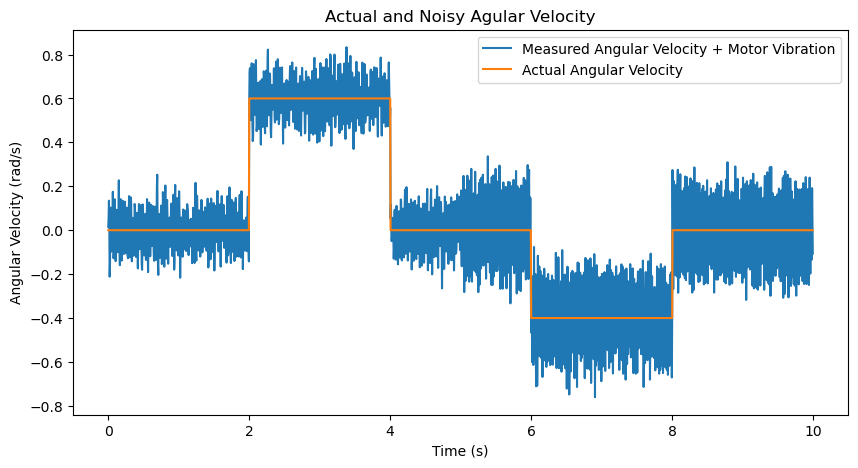

In [9]:
# Generating vibration signal
motor_freq = np.where(t < 5, 35, 55)
motor_amplitude = np.where(t < 5, 0.12, 0.22)
motor_phase = 2 * np.pi * np.concatenate(([0], np.cumsum(motor_freq[:-1]) / fs))
motor_vibration = motor_amplitude * np.sin(motor_phase)

gyro_noisy = omega_true + sensor_noise + motor_vibration

# Plotting omega_true and gyro_noisy vs time
plt.figure(figsize=(10, 5))
plt.plot(t, gyro_noisy, label="Measured Angular Velocity + Motor Vibration")
plt.plot(t, omega_true, label="Actual Angular Velocity")
plt.title("Actual and Noisy Agular Velocity")
plt.xlabel("Time (s)")
plt.ylabel("Angular Velocity (rad/s)")
plt.legend()
plt.show()

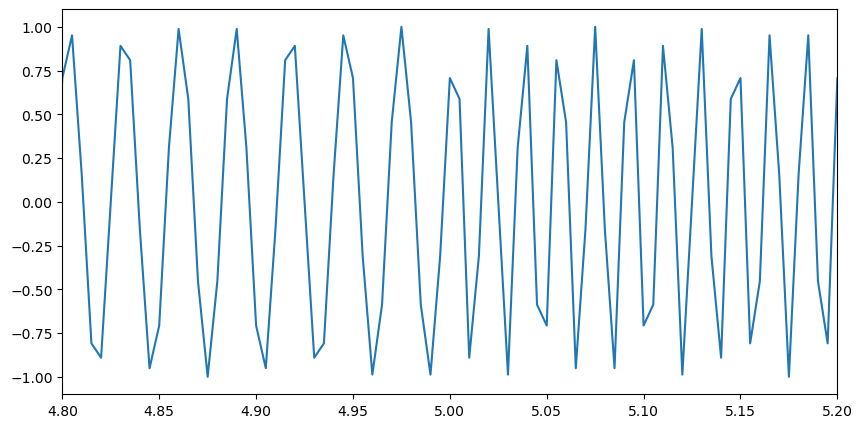

In [13]:
# Creating reference signal
phase_offset = np.pi / 4
motor_ref = np.sin(motor_phase + phase_offset)
# Here, I deliberatelt don't multiply the reference by motor_amplitude 
# because the adaptive filter is going o learn the amplitude relationship
# furthermore, I introduced a 45 degree phase difference, so the reference isn't identical to the vibration
# conseuenctly I will use a two-tap LMS and NLMS to compensate for the phase difference

# Plotting motor_ref over time to confirm that the frequency changes at 5 seconds
plt.figure(figsize=(10, 5))
plt.plot(t, motor_ref)
plt.xlim(4.8, 5.2)
plt.show()

Before 5 seconds oscillations are fatrther part, and after 5 seconds they are closer together

## Designing FIR low-pass filter

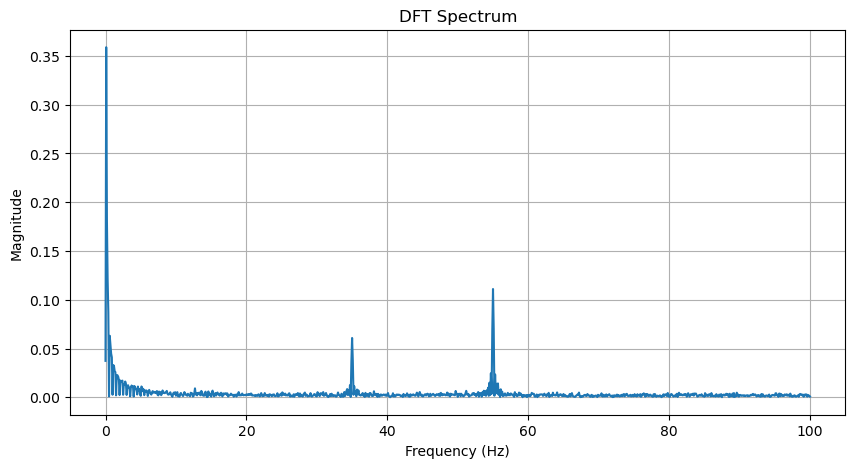

In [16]:
freq = np.fft.rfftfreq(N, d=1/fs)
magnitude = np.abs(np.fft.rfft(gyro_noisy)) / N
magnitude[1:-1] *= 2
plt.figure(figsize=(10, 5))
plt.plot(freq, magnitude)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude")
plt.title("DFT Spectrum")
plt.grid(True)
plt.show()

Near 0 Hz strong low-frequency energy is observed because of the robot's actual turning motion

35 Hz and 55 Hz show motor vibration before and after 5 seconds

Small flutuations across the spectrum show random sensor noise and sigal transitions

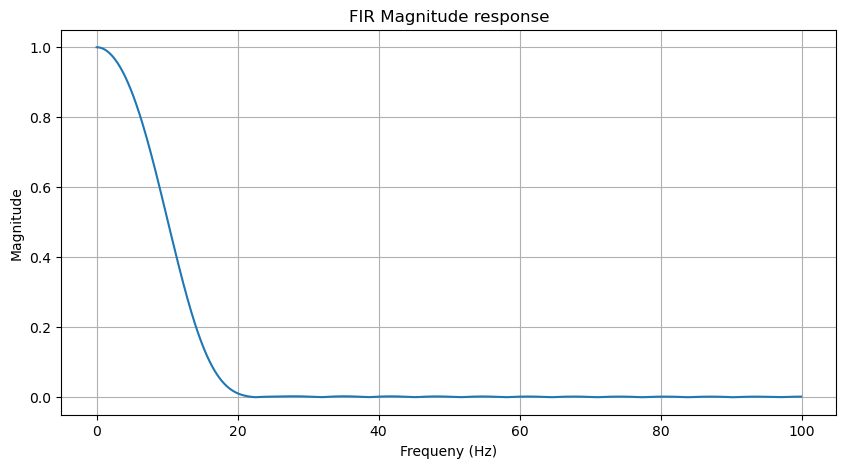

In [24]:
# low-pass FIR filter
from scipy.signal import firwin, freqz
numtaps = 31
cutoff = 10
b_fir = firwin(numtaps, cutoff, fs=fs)

f, H = freqz(b_fir, [1], worN=2048, fs=fs)
magnitude_fir = np.abs(H)
plt.figure(figsize=(10, 5))
plt.plot(f, magnitude_fir)
plt.xlabel("Frequeny (Hz)")
plt.ylabel("Magnitude")
plt.title("FIR Magnitude response")
plt.grid(True)
plt.show()

0 Hz is preserved

10 Hz cutoff regio

20 Hz strong attenuation

35 Hz and 55 Hz motor vibration strongly suppressed

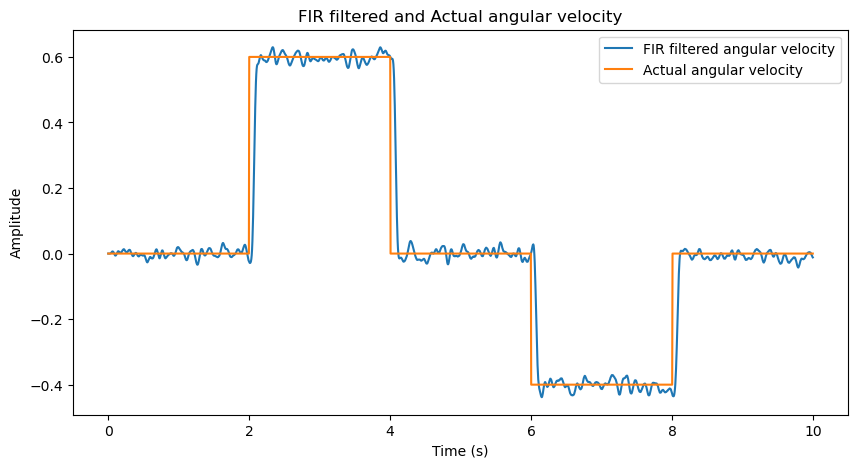

In [20]:
from scipy.signal import lfilter
gyro_fir = lfilter(b_fir, [1], gyro_noisy)
plt.figure(figsize=(10, 5))
plt.plot(t, gyro_fir, label="FIR filtered angular velocity")
plt.plot(t, omega_true, label="Actual angular velocity")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.title("FIR filtered and Actual angular velocity")
plt.legend()
plt.show()

The filter has substantially reduced the noise

But there is a problem with this filter which is group delay:

    since it has 31 coefficients, its group delay is 31 - 1 / 2 = 15 samples 
    with fs = 200, we calculate that the group delay is 0.75 milliseconds
This means the FIR filtered signal will be delayed by 0.075 milliseconds

#### RMSE

In [22]:
rmse_noisy = np.sqrt(np.mean((gyro_noisy - omega_true) ** 2))
rmse_fir = np.sqrt(np.mean((gyro_fir - omega_true) ** 2))
print(f"RMSE before filtering = {rmse_noisy:.4f}")
print(f"RMSE after filtering = {rmse_fir:.4f}")

RMSE before filtering = 0.1354
RMSE after filtering = 0.0849


Conclusion:

    The FIR filter reduces the measurement error, but some error remains because of sensor noise, filter's delay, and distortion around sudden turns

## Designing IIR low-pass filter

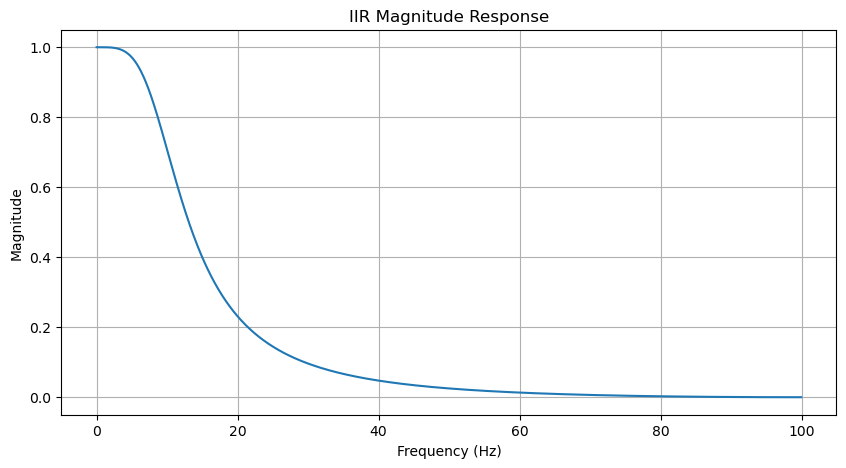

In [25]:
from scipy.signal import butter

order= 2
cutoff = 10
b_iir, a_iir = butter(order, cutoff, btype="lowpass", fs=fs)

f, H = freqz(b_iir, a_iir, worN=2048, fs=fs)
magnitude_iir = np.abs(H)
plt.figure(figsize=(10, 5))
plt.plot(f, magnitude_iir)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude")
plt.title("IIR Magnitude Response")
plt.grid(True)
plt.show()

At 35 Hz, the IIR filter still passes a small amount of motor vibration, while the 31-tap FIR filter has a gain much closer to zero

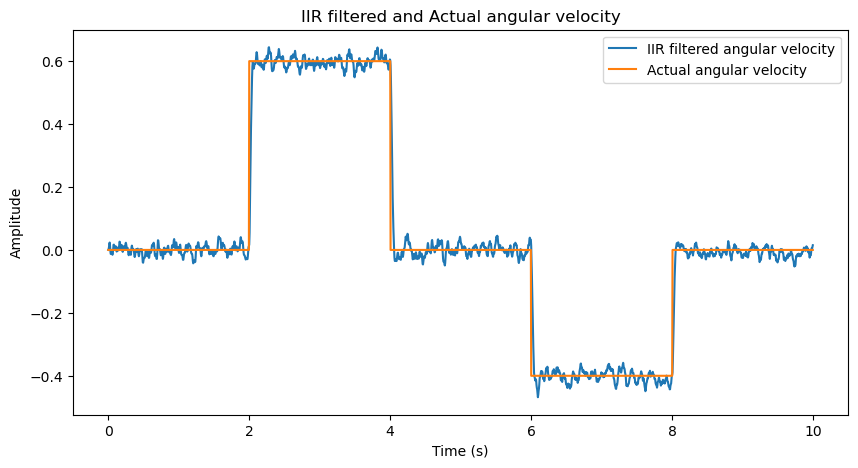

In [26]:
gyro_iir = lfilter(b_iir, a_iir, gyro_noisy)
plt.figure(figsize=(10, 5))
plt.plot(t, gyro_iir, label="IIR filtered angular velocity")
plt.plot(t, omega_true, label="Actual angular velocity")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.title("IIR filtered and Actual angular velocity")
plt.legend()
plt.show()

##### RMSE

In [28]:
rmse_iir = np.sqrt(np.mean((gyro_iir - omega_true) ** 2))
print(f"RMSE before filtering = {rmse_noisy:.4f}")
print(f"RMSE after filtering = {rmse_iir:.4f}")

RMSE before filtering = 0.1354
RMSE after filtering = 0.0451


### Important Conclusion:

However, the second order IIR filter does not strongly suppress high frequencies, it performs considerably better than the 31-tap FIR filter for this gyroscope signal

## Designing two-tap LMS

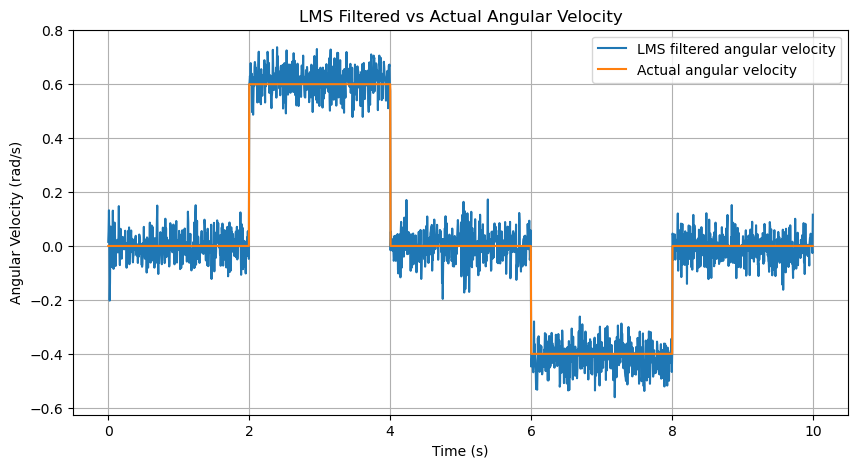

In [31]:
mu = 0.05
w = np.zeros(2)
y_lms = np.zeros(N)
e_lms = np.zeros(N)
w_history_lms = np.zeros((N, 2))
for n in range(1, N):
    x_vector = np.array([motor_ref[n], motor_ref[n-1]])
    y_lms[n] = np.dot(w, x_vector)
    e_lms[n] = gyro_noisy[n] - y_lms[n]
    w = w + mu * e_lms[n] * x_vector
    w_history_lms[n] = w
# Since loop starts at n=1, e_lms[0] remains zero, so:
e_lms[0] = gyro_noisy[0]

plt.figure(figsize=(10, 5))
plt.plot(t, e_lms, label="LMS filtered angular velocity")
plt.plot(t, omega_true, label="Actual angular velocity")
plt.xlabel("Time (s)")
plt.ylabel("Angular Velocity (rad/s)")
plt.title("LMS Filtered vs Actual Angular Velocity")
plt.legend()
plt.grid(True)
plt.show()

LMS does not smooth the fluctuations the way the IIR and FIR filters do

This is the limitation of the LMS filter because it just subtracts interference using the motor reference. It cannot reduce sensor noise because the reference is correlated with motor vibration, not with independent white sensor noise.

#### RMSE

In [34]:
rmse_lms = np.sqrt(np.mean((e_lms - omega_true) ** 2))
print(f"RMSE before filtering = {rmse_noisy:.4f}")
print(f"RMSE after filtering = {rmse_lms:.4f}")

RMSE before filtering = 0.1354
RMSE after filtering = 0.0535


LMS filter performs betterthan FIR, but the IIR filter still has the lowest RMSE

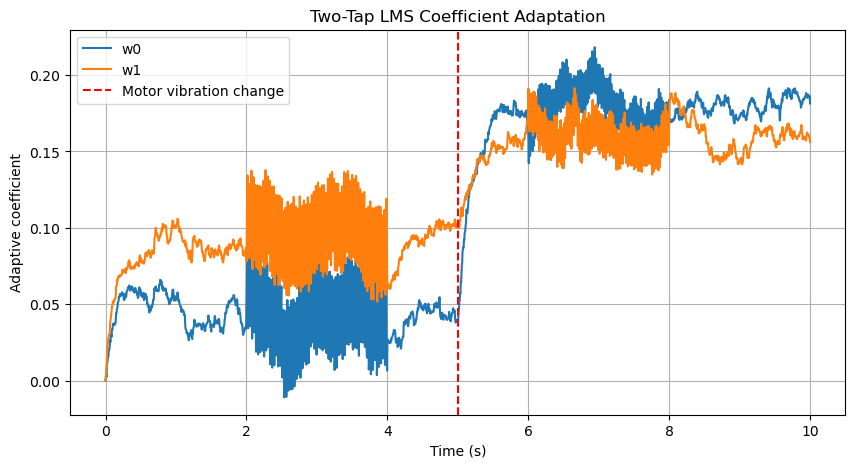

In [35]:
# Examine the coefficient adaptation
plt.figure(figsize=(10, 5))
plt.plot(t, w_history_lms[:, 0], label="w0")
plt.plot(t, w_history_lms[:, 1], label="w1")
plt.axvline(5, color="red", linestyle="--", label="Motor vibration change")
plt.xlabel("Time (s)")
plt.ylabel("Adaptive coefficient")
plt.title("Two-Tap LMS Coefficient Adaptation")
plt.legend()
plt.grid(True)
plt.show()

## Designing two-tap NLMS filter

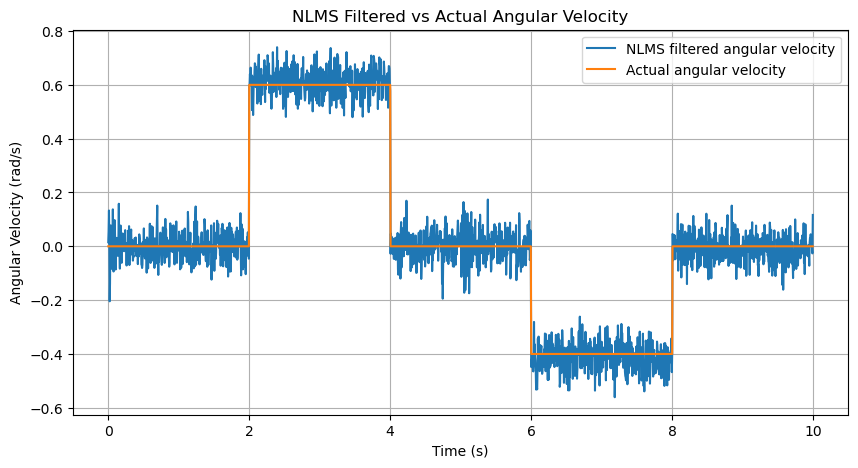

In [40]:
mu = 0.05
epsilon = 0.1
w = np.zeros(2)
y_nlms = np.zeros(N)
e_nlms = np.zeros(N)
w_history_nlms = np.zeros((N, 2))
e_nlms[0] = gyro_noisy[0]
for n in range(1, N):
    x_vector = np.array([motor_ref[n], motor_ref[n-1]])
    y_nlms[n] = np.dot(x_vector, w)
    e_nlms[n] = gyro_noisy[n] - y_nlms[n]
    w = w + (mu * e_nlms[n] * x_vector) / (epsilon + (np.dot(x_vector, x_vector)))
    w_history_nlms[n] = w

plt.figure(figsize=(10, 5))
plt.plot(t, e_nlms, label="NLMS filtered angular velocity")
plt.plot(t, omega_true, label="Actual angular velocity")
plt.xlabel("Time (s)")
plt.ylabel("Angular Velocity (rad/s)")
plt.title("NLMS Filtered vs Actual Angular Velocity")
plt.legend()
plt.grid(True)
plt.show()
    

#### RMSE

In [41]:
rmse_nlms = np.sqrt(np.mean((e_nlms - omega_true) ** 2))
print(f"RMSE before filtering = {rmse_noisy:.4f}")
print(f"RMSE after filtering = {rmse_nlms:.4f}")

RMSE before filtering = 0.1354
RMSE after filtering = 0.0533


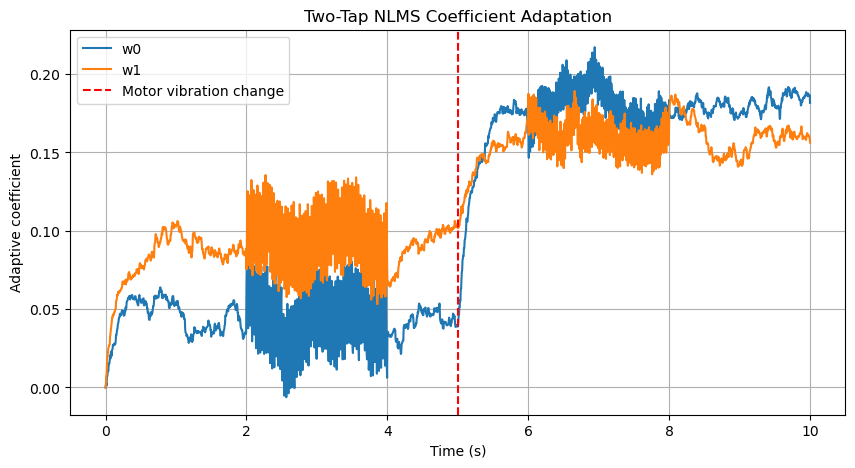

In [42]:
# Examine the coefficient adaptation
plt.figure(figsize=(10, 5))
plt.plot(t, w_history_nlms[:, 0], label="w0")
plt.plot(t, w_history_nlms[:, 1], label="w1")
plt.axvline(5, color="red", linestyle="--", label="Motor vibration change")
plt.xlabel("Time (s)")
plt.ylabel("Adaptive coefficient")
plt.title("Two-Tap NLMS Coefficient Adaptation")
plt.legend()
plt.grid(True)
plt.show()

LMS and NLMS filters approximately achieve similar results

IIR provides the lowest RMSE

## Comparing the filters during a robot turn

This is particularly important for robotics because RMSE alone doesn't tell us how quickly a filter responds to changes in agular velocity

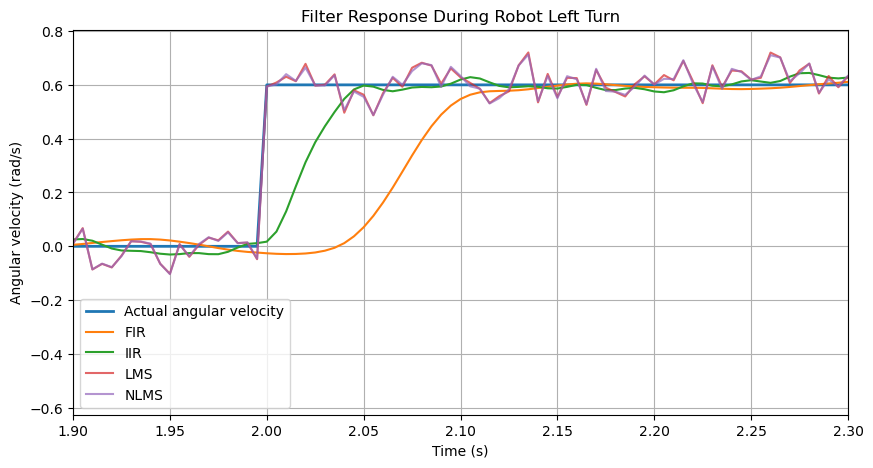

In [43]:
plt.figure(figsize=(10, 5))

plt.plot(t, omega_true, label="Actual angular velocity", linewidth=2)
plt.plot(t, gyro_fir, label="FIR")
plt.plot(t, gyro_iir, label="IIR")
plt.plot(t, e_lms, label="LMS", alpha=0.7)
plt.plot(t, e_nlms, label="NLMS", alpha=0.7)

plt.xlim(1.9, 2.3)
plt.xlabel("Time (s)")
plt.ylabel("Angular velocity (rad/s)")
plt.title("Filter Response During Robot Left Turn")
plt.legend()
plt.grid(True)
plt.show()

This shows that the filter with lowest RMSE is not necessarily the filter that responds fastest to changes in robot motion

FIR: Provides a smoother measurement but introduces a noticeable delay.
IIR: Provides good noise reduction with a faster response in this experiment.
LMS/NLMS: Preserve rapid changes in angular velocity but leave more random noise.

For this current simulation, IIR appears to offer the best overall balance